In [133]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import numpy as np

# *Dataset: Student Alcohol Consumption*

Os dados foram obtidos por meio de uma pesquisa com estudantes do ensino secundário que cursavam Matemática e Língua Portuguesa. O conjunto de dados contém diversas **informações sobre os aspectos sociais, o gênero e os hábitos de estudo dos estudantes.**

# *Dicionário*

Atributos presentes nos dois conjuntos de dados: `student-mat.csv` (curso de Matemática) e `student-por.csv` (curso de Língua Portuguesa).

1. escola — Escola do estudante (binária: `'GP'` — Gabriel Pereira ou `'MS'` — Mousinho da Silveira).

2. sexo — Sexo do estudante (binária: `'F'` — feminino ou `'M'` — masculino).

3. idade — Idade do estudante (numérica: de 15 a 22 anos).

4. regiao — Tipo de endereço residencial do estudante (binária: `'U'` — urbano ou `'R'` — rural).

5. tamanho_familia — Tamanho da família (binária: `'LE3'` — menor ou igual a 3 pessoas ou `'GT3'` — maior que 3 pessoas).

6. convivencia_pais — Situação de convivência dos pais (binária: `'T'` — moram juntos ou `'A'` — moram separados).

7. educacao_mae — Escolaridade da mãe (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

8. educacao_pai — Escolaridade do pai (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

9. trabalho_mae — Profissão da mãe (categórica nominal: `'teacher'` — professora; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

10. trabalho_pai — Profissão do pai (categórica nominal: `'teacher'` — professor; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

11. escolha_escola — Motivo para escolher a escola (categórica nominal: proximidade de `'home'` — casa; reputação da escola (`'reputation'`); preferência pelo curso (`'course'`); ou outro motivo (`'other'`)).

12. guardiao_legal — Responsável legal pelo estudante (categórica nominal: `'mother'` — mãe; `'father'` — pai; ou `'other'` — outro).

13. tempo_viagem_escola — Tempo de deslocamento de casa até a escola (numérica: 1 — menos de 15 minutos; 2 — de 15 a 30 minutos; 3 — de 30 minutos a 1 hora; ou 4 — mais de 1 hora).

14. tempo_estudo_semanal — Tempo semanal de estudo (numérica: 1 — menos de 2 horas; 2 — de 2 a 5 horas; 3 — de 5 a 10 horas; ou 4 — mais de 10 horas).

15. nº_reprovacoes — Número de reprovações anteriores (numérica: indica o número de reprovações quando 1≤n<31 \leq n < 31≤n<3; caso contrário, o valor é 4).

16. apoio_escola — Recebe apoio educacional extra da escola (binária: sim ou não).

17. apoio_familiar — Recebe apoio educacional da família (binária: sim ou não).

18. paid — Participa de aulas particulares pagas na disciplina correspondente (Matemática ou Língua Portuguesa) (binária: sim ou não).

19. participacao_atividades_extras — Participa de atividades extracurriculares (binária: sim ou não).

20. edu_infantil — Frequentou a educação infantil (binária: sim ou não).

21. desejo_de_ensino superior — Deseja cursar o ensino superior (binária: sim ou não).

22. acesso_internet_casa — Possui acesso à internet em casa (binária: sim ou não).

23. relacionamento_amoroso — Está em um relacionamento amoroso (binária: sim ou não).

24. qualidade_relacao_familiar — Qualidade das relações familiares (numérica: de 1 — muito ruim a 5 — excelente).

25. tempo_livre — Tempo livre após as aulas (numérica: de 1 — muito baixo a 5 — muito alto).

26. frequencia_saida_com_amigos — Frequência com que sai com os amigos (numérica: de 1 — muito baixa a 5 — muito alta).

27. consumo_alcool_semana — Consumo de álcool durante os dias úteis (numérica: de 1 — muito baixo a 5 — muito alto).

28. consumo_alcool_fim_de_semana — Consumo de álcool durante os fins de semana (numérica: de 1 — muito baixo a 5 — muito alto).

29. estado_saude_atual — Estado de saúde atual (numérica: de 1 — muito ruim a 5 — muito bom).

30. faltas — Número de faltas escolares (numérica: de 0 a 93).

31. nota_1p — Nota do primeiro período (numérica: de 0 a 20).

32. nota_2p — Nota do segundo período (numérica: de 0 a 20).

33. nota_final — Nota final (numérica: de 0 a 20; variável-alvo para previsão).

In [ ]:
df_port = pd.read_csv('files/student-por.csv')

In [ ]:
# Retirando algumas colunas.
df_port = df_port.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])

# Renomeando as colunas sobrantes:
df_port = df_port.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})

## Analisar como as variáveis nominais se relacionam com as notas
- escola, sexo, regiao, desejo_de_ensino_superior, tamanho_familia, convivencia_pais, trabalho_mae, trabalho_pai, motivo_escola, guardiao_legal.

# Mapa de calor que plota a relação das variáveis com as notas

In [ ]:
def ajustar_bh(p):
    # correção para vários testes (Benjamini-Hochberg)
    p = np.asarray(p, dtype=float)
    n = len(p)
    ordem = np.argsort(p)
    ajustado = np.empty(n)
    minimo = 1.0
    for i in range(n - 1, -1, -1):
        idx = ordem[i]
        minimo = min(minimo, p[idx] * n / (i + 1))
        ajustado[idx] = minimo
    return ajustado


def relacao_com_notas(df, col_notas, nominais, disciplina=""):
    faltando = [c for c in col_notas + nominais if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) para cada variável e cada nota: teste de Kruskal-Wallis + tamanho do efeito
    linhas = []
    for nota in col_notas:
        for col in nominais:
            grupos = [g[nota].values for _, g in df.groupby(col)]
            if len(grupos) < 2:
                continue
            h, p = stats.kruskal(*grupos)
            n = sum(len(g) for g in grupos)
            eps2 = h / ((n ** 2 - 1) / (n + 1))          # tamanho do efeito (epsilon²)
            medias = df.groupby(col)[nota].mean()
            linhas.append({
                "nota": nota, "variavel": col,
                "tamanho_efeito": round(max(eps2, 0), 3), "p": p,
                "categoria_maior_media": medias.idxmax(), "media_maior": round(medias.max(), 1),
                "categoria_menor_media": medias.idxmin(), "media_menor": round(medias.min(), 1),
                "n_menor_grupo": int(df[col].value_counts().min()),
            })
    res = pd.DataFrame(linhas)
    res["p_ajustado"] = ajustar_bh(res["p"]).round(4)
    res["real?"] = np.where(res["p_ajustado"] < 0.05, "sim", "não")

    # 2) texto: tabela resumo (variável x nota)
    efeito = res.pivot(index="variavel", columns="nota", values="tamanho_efeito")[col_notas]
    efeito = efeito.loc[efeito.mean(axis=1).sort_values(ascending=False).index]
    real = res.pivot(index="variavel", columns="nota", values="real?")[col_notas].loc[efeito.index]
    anot = efeito.round(3).astype(str) + real.map(lambda x: "*" if x == "sim" else "")

    print("=" * 70)
    print(f"{disciplina}: relação de cada variável com as notas")
    print("(tamanho do efeito; * = diferença que não parece acaso)")
    print("=" * 70)
    print(anot.to_string())

    print("\nDetalhe: categoria com a maior e a menor média de nota")
    detalhe = res[["nota", "variavel", "tamanho_efeito", "p_ajustado", "real?",
                   "categoria_maior_media", "media_maior", "categoria_menor_media",
                   "media_menor", "n_menor_grupo"]]
    print(detalhe.sort_values(["nota", "tamanho_efeito"], ascending=[True, False]).to_string(index=False))

    # 3) gráfico: mapa de calor do tamanho do efeito
    plt.figure(figsize=(7, 0.55 * len(efeito) + 2))
    sns.heatmap(efeito, annot=anot, fmt="", cmap="Reds", vmin=0, vmax=0.15,
                linewidths=0.5, cbar_kws={"label": "tamanho do efeito (0 = nenhum)"})
    plt.title(f"{disciplina}: quanto cada variável se relaciona com as notas\n(* = não parece acaso)")
    plt.ylabel("")
    plt.xlabel("")
    plt.tight_layout()
    plt.show()
    return res

nominais = ["escola", "sexo", "regiao", "desejo_de_ensino_superior", "tamanho_familia",
            "convivencia_pais", "trabalho_mae", "trabalho_pai", "motivo_escola", "guardiao_legal"]
notas = ["nota_1p", "nota_2p", "nota_final"]

Português: relação de cada variável com as notas
(tamanho do efeito; * = diferença que não parece acaso)
nota                      nota_1p nota_2p nota_final
variavel                                            
desejo_de_ensino_superior  0.129*   0.12*     0.125*
escola                     0.091*  0.072*     0.081*
trabalho_mae               0.055*  0.051*     0.057*
motivo_escola              0.045*  0.049*     0.049*
trabalho_pai               0.034*   0.03*     0.027*
regiao                     0.027*  0.026*     0.029*
guardiao_legal             0.022*  0.014*     0.012*
sexo                       0.014*  0.015*     0.018*
tamanho_familia             0.002   0.001        0.0
convivencia_pais              0.0     0.0        0.0

Detalhe: categoria com a maior e a menor média de nota
      nota                  variavel  tamanho_efeito  p_ajustado real? categoria_maior_media  media_maior categoria_menor_media  media_menor  n_menor_grupo
   nota_1p desejo_de_ensino_superior           

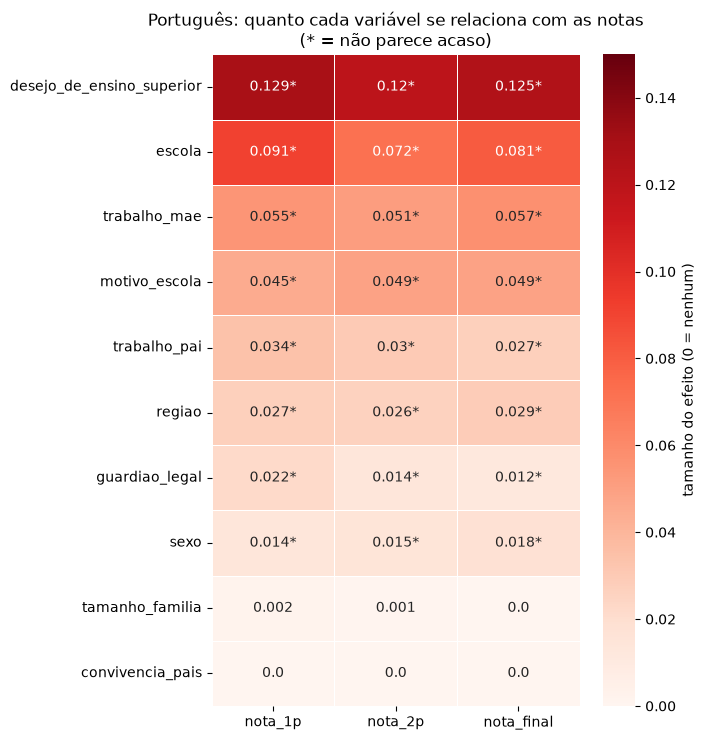

In [ ]:
res_port = relacao_com_notas(df_port, notas, nominais, disciplina="Português")

Diante do mapa de calor, retiro as variáveis convivência_pais, tamanho_familia e guardiao_legal pela sua pequena relação com as notas.

In [ ]:
nominais_foco = ["escola", "regiao", "sexo" "desejo_de_ensino_superior", "trabalho_mae", "trabalho_pai", "motivo_escola"]

# Como as variavéis se distribuem entre o primeiro e quarto quartil - Q1 e Q4

In [ ]:
def criar_grupos(df, col_nota):
    # Q1 = nota MENOR que o 1º quartil | Q4 = nota MAIOR que o 3º quartil
    q1, q3 = df[col_nota].quantile([0.25, 0.75])
    grupo = np.select([df[col_nota] < q1, df[col_nota] > q3], ["Q1", "Q4"], default="meio")
    return grupo, q1, q3


def comparar_variavel(df, col_nota, col):
    grupo, q1, q3 = criar_grupos(df, col_nota)
    d = df.assign(grupo=grupo)
    d = d[d["grupo"] != "meio"]                      # ignora o meio
    tab = pd.crosstab(d[col], d["grupo"])            # contagens por categoria
    for g in ["Q1", "Q4"]:
        if g not in tab:
            tab[g] = 0
    if tab.shape[0] < 2:                             # só 1 categoria: nada a comparar
        return None
    pct = tab / tab.sum() * 100                      # % da categoria DENTRO de cada grupo
    dif = pct["Q1"] - pct["Q4"]
    chi2, p_chi2, _, _ = stats.chi2_contingency(tab, correction=False)
    p = stats.fisher_exact(tab)[1] if tab.shape == (2, 2) else p_chi2
    v = np.sqrt(chi2 / tab.values.sum() / (min(tab.shape) - 1))   # V de Cramér
    detalhe = pd.DataFrame({"n_Q1": tab["Q1"], "n_Q4": tab["Q4"],
                            "%_Q1": pct["Q1"].round(1), "%_Q4": pct["Q4"].round(1),
                            "dif_pp": dif.round(1)})
    return detalhe, v, p

def analisar_extremos(df, col_notas, nominais, disciplina="", mostrar_detalhes=False):
    faltando = [c for c in col_notas + nominais if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) calcula tudo
    detalhes, linhas = {}, []
    for nota in col_notas:
        for col in nominais:
            r = comparar_variavel(df, nota, col)
            if r is None:
                continue
            detalhe, v, p = r
            detalhes[(nota, col)] = detalhe
            cat = detalhe["dif_pp"].abs().idxmax()   # categoria com a maior diferença
            linhas.append({"nota": nota, "variavel": col, "V": round(v, 3), "p": p,
                           "categoria": cat, "%_Q1": detalhe.loc[cat, "%_Q1"],
                           "%_Q4": detalhe.loc[cat, "%_Q4"], "dif_pp": detalhe.loc[cat, "dif_pp"]})
    rank = pd.DataFrame(linhas)
    rank["p_ajustado"] = ajustar_bh(rank["p"]).round(4)
    rank["real?"] = np.where(rank["p_ajustado"] < 0.05, "sim", "não")
    rank = rank.drop(columns="p")

    # 2) texto: quartis, tamanho dos grupos e ranking das variáveis
    for nota in col_notas:
        grupo, q1, q3 = criar_grupos(df, nota)
        print("=" * 75)
        print(f"{disciplina} | {nota}")
        print("=" * 75)
        print(f"Q1 (25%) = {q1} | Q3 (75%) = {q3} | alunos com nota zero: {(df[nota] == 0).sum()}")
        print(f"Grupo Q1 (nota < {q1}): {(grupo == 'Q1').sum()} alunos | "
              f"Grupo Q4 (nota > {q3}): {(grupo == 'Q4').sum()} alunos | "
              f"meio (ignorado): {(grupo == 'meio').sum()}")
        print("\nVariáveis ordenadas pelo quanto separam o Q1 do Q4:")
        print(rank[rank["nota"] == nota].drop(columns="nota")
              .sort_values("V", ascending=False).to_string(index=False))
        if mostrar_detalhes:
            for col in nominais:
                if (nota, col) in detalhes:
                    print(f"\n--- {nota} por {col} ---")
                    print(detalhes[(nota, col)].to_string())

    # 3) gráficos: uma figura por variável, uma coluna por prova
    for col in nominais:
        if not all((nota, col) in detalhes for nota in col_notas):
            continue
        fig, axes = plt.subplots(1, len(col_notas), figsize=(5.5 * len(col_notas), 4), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, nota in zip(axes, col_notas):
            det = detalhes[(nota, col)]
            linha = rank[(rank["nota"] == nota) & (rank["variavel"] == col)].iloc[0]
            x = np.arange(len(det))
            barras_q1 = ax.bar(x - 0.2, det["%_Q1"], width=0.4, color="tab:red", label="Q1 (piores)")
            barras_q4 = ax.bar(x + 0.2, det["%_Q4"], width=0.4, color="tab:blue", label="Q4 (melhores)")
            ax.bar_label(barras_q1, fmt="%.0f%%", fontsize=8)
            ax.bar_label(barras_q4, fmt="%.0f%%", fontsize=8)
            ax.set_xticks(x)
            ax.set_xticklabels(det.index.astype(str))
            ax.set_ylim(0, 110)
            ax.set_title(f"{nota} (V={linha['V']:.2f}, real? {linha['real?']})")
            ax.set_ylabel("% dos alunos do grupo")
        axes[0].legend(loc="upper left", fontsize=8)
        fig.suptitle(f"{disciplina} - {col}", fontsize=13)
        plt.tight_layout(rect=[0, 0, 1, 0.94])
        plt.show()

Português | nota_1p
Q1 (25%) = 10.0 | Q3 (75%) = 13.0 | alunos com nota zero: 1
Grupo Q1 (nota < 10.0): 157 alunos | Grupo Q4 (nota > 13.0): 152 alunos | meio (ignorado): 340

Variáveis ordenadas pelo quanto separam o Q1 do Q4:
                 variavel     V categoria  %_Q1  %_Q4  dif_pp  p_ajustado real?
desejo_de_ensino_superior 0.425        no  32.5   0.7    31.8      0.0000   sim
                   escola 0.366        GP  39.5  75.7   -36.2      0.0000   sim
             trabalho_mae 0.310   at_home  31.2  13.2    18.1      0.0000   sim
            motivo_escola 0.270    course  56.1  36.8    19.2      0.0002   sim
             trabalho_pai 0.224   teacher   1.9   9.9    -8.0      0.0066   sim
                   regiao 0.203         R  42.0  23.0    19.0      0.0010   sim
           guardiao_legal 0.196     other  12.1   2.6     9.5      0.0050   sim
                     sexo 0.172         F  51.6  68.4   -16.8      0.0050   sim
          tamanho_familia 0.096       GT3  75.2  66.

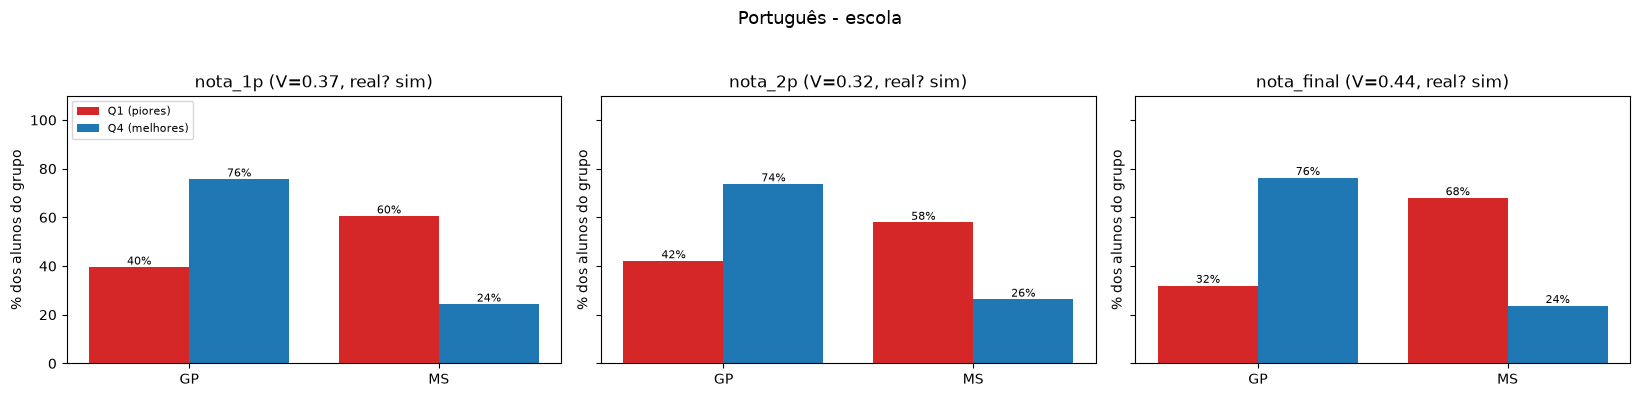

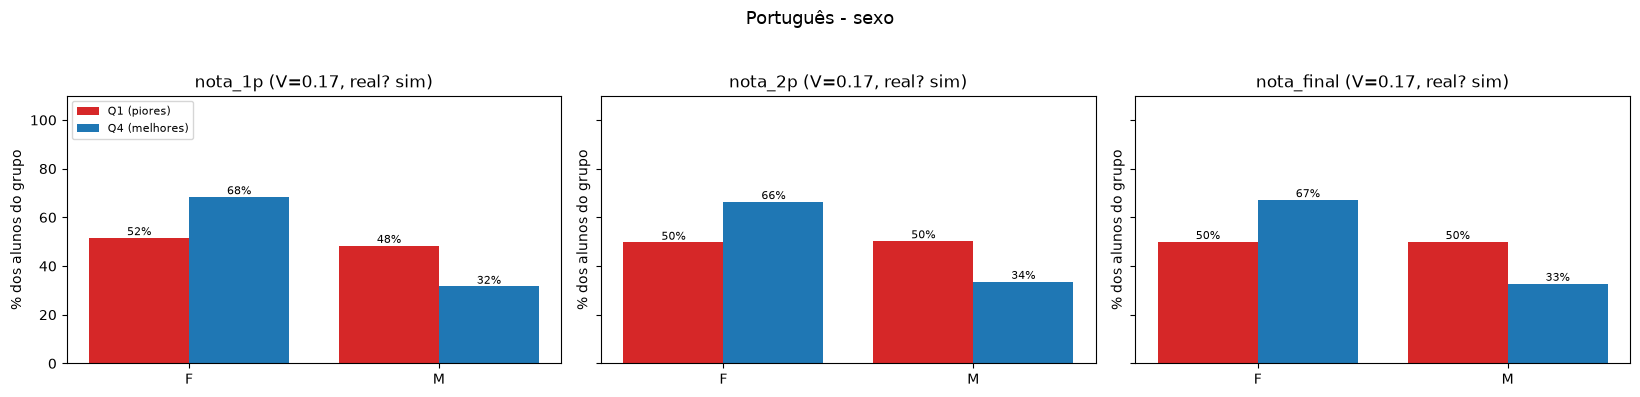

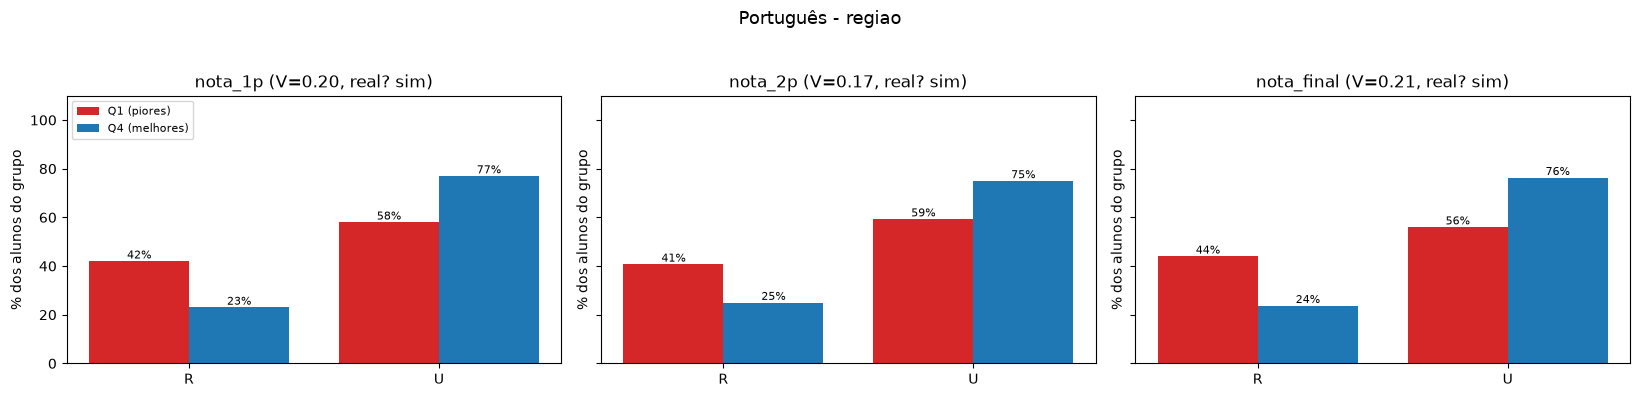

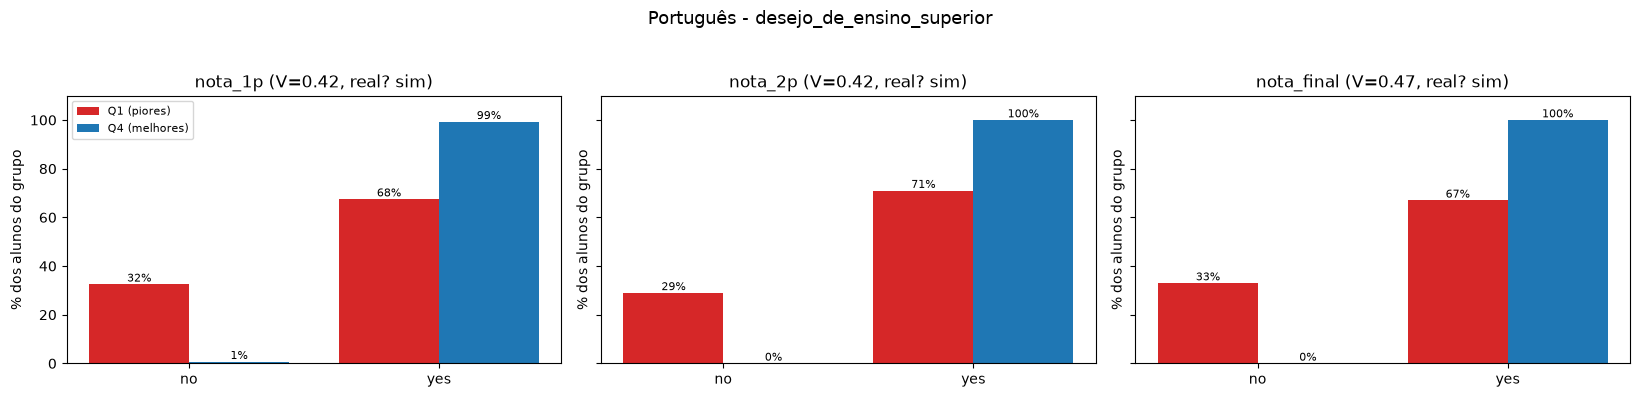

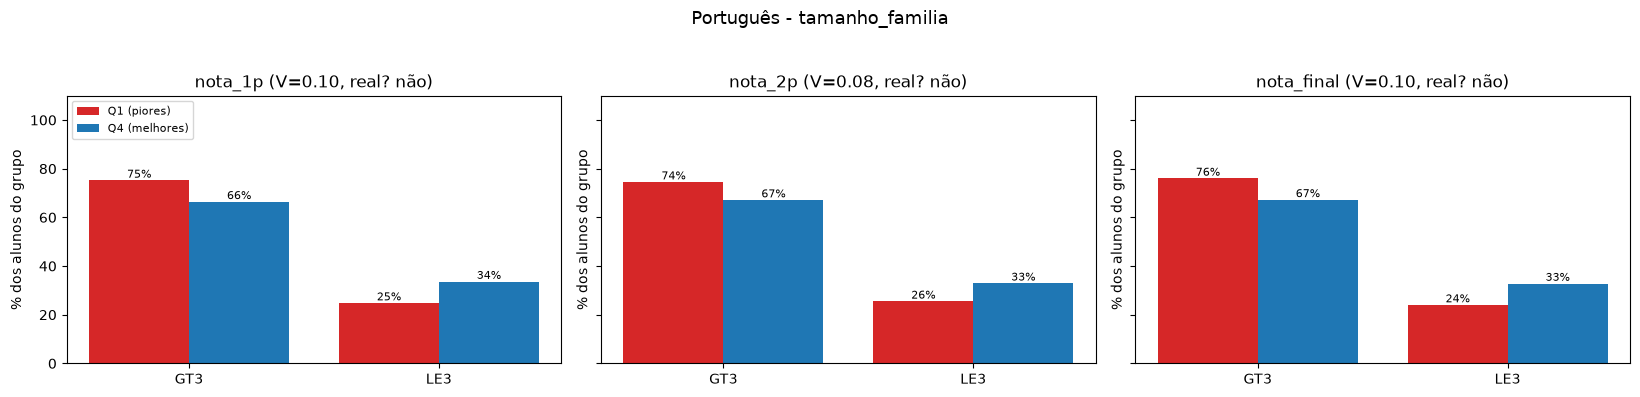

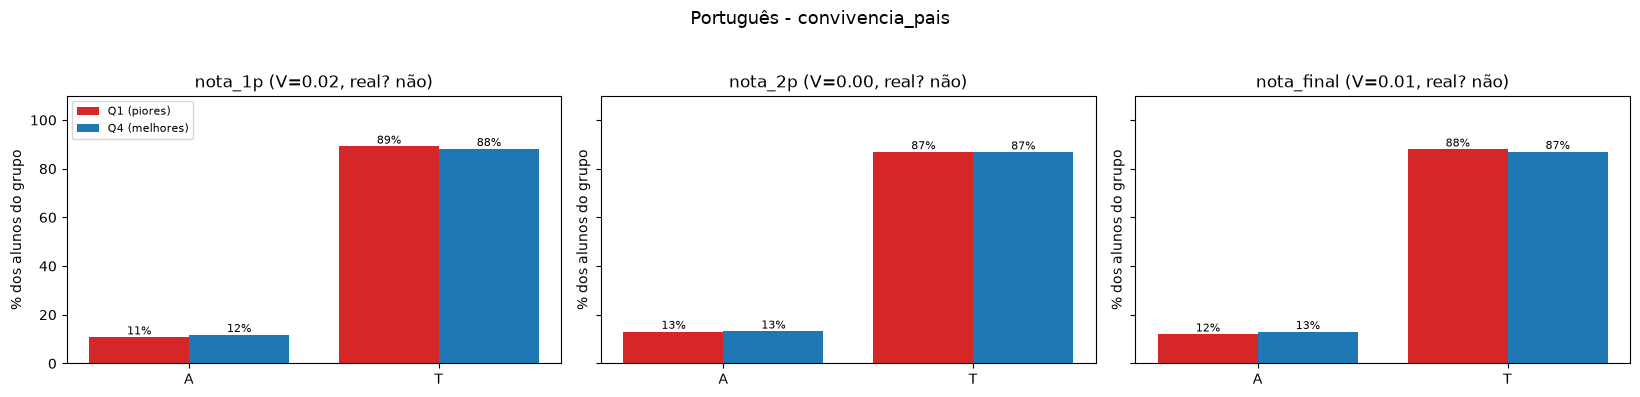

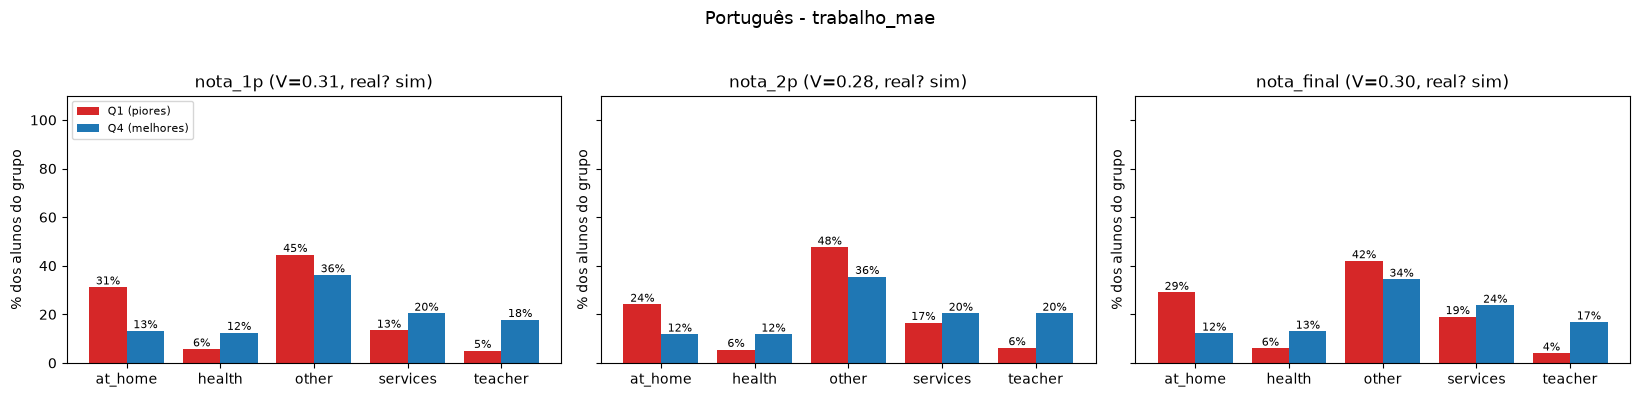

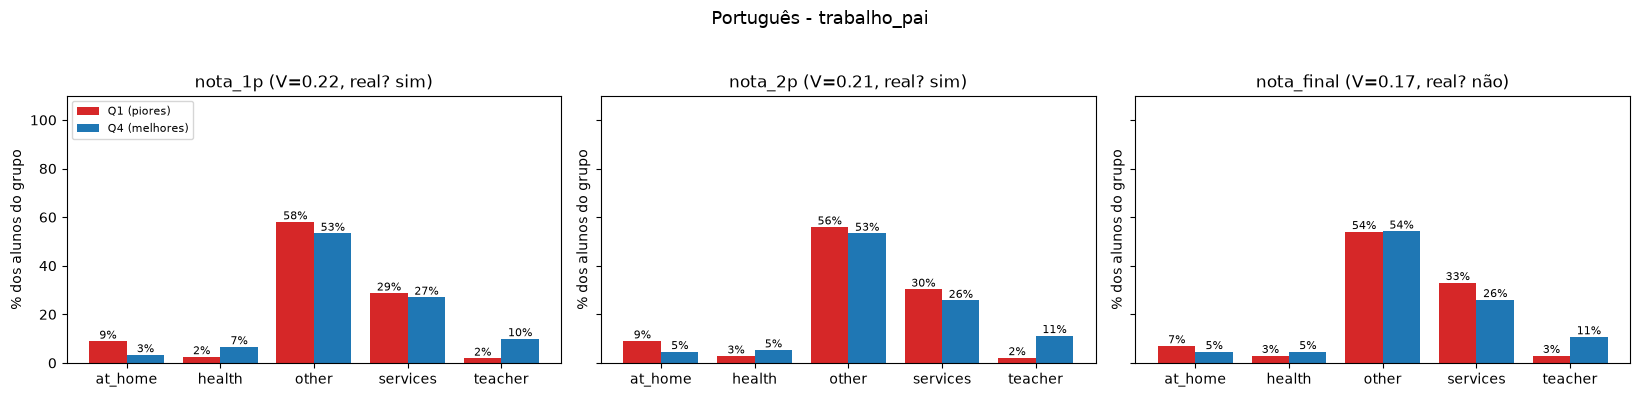

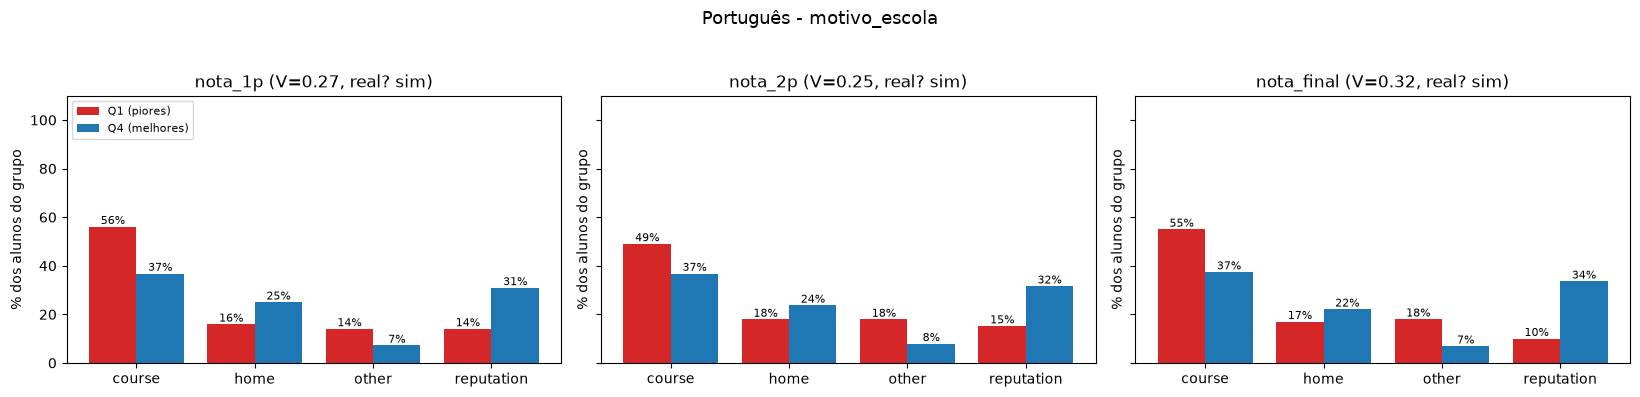

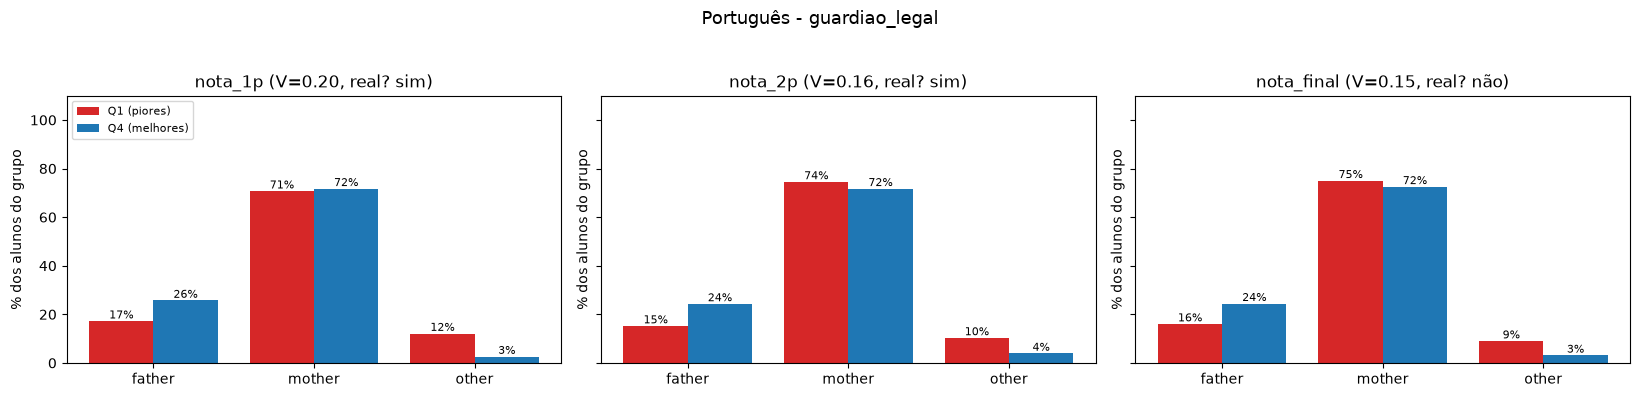

In [ ]:
analisar_extremos(df_port, notas, nominais, disciplina="Português")

# Observação de como se comportam  as notas de quem deseja o ensino superior nas escolas.

In [ ]:
def boxplots_por_lente(df, col_notas, col_foco, col_lente, titulo=""):
    faltando = [c for c in col_notas + [col_foco, col_lente] if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    cats_foco = sorted(df[col_foco].dropna().unique())     # ex.: no, yes
    cats_lente = sorted(df[col_lente].dropna().unique())   # ex.: GP, MS

    # 1) texto: tamanho dos grupos e médias das notas
    resumo = df.groupby([col_lente, col_foco])[col_notas].mean().round(2)
    resumo.insert(0, "n", df.groupby([col_lente, col_foco]).size())
    print("=" * 70)
    print(f"{titulo}: média das notas por {col_lente} e {col_foco}")
    print("=" * 70)
    print(resumo.to_string())

    # 2) texto: diferença de média entre as duas categorias do foco, dentro de cada lente
    if len(cats_foco) == 2:
        a, b = cats_foco
        medias = df.groupby([col_lente, col_foco])[col_notas].mean()
        dif = pd.DataFrame({nota: [medias.loc[(l, b), nota] - medias.loc[(l, a), nota]
                                   for l in cats_lente] for nota in col_notas},
                           index=cats_lente).round(2)
        dif.index.name = col_lente
        print(f"\nDiferença de média ({b} - {a}) dentro de cada {col_lente}:")
        print(dif.to_string())

    # 3) gráfico: uma linha por categoria da lente, uma coluna por nota
    fig, axes = plt.subplots(len(cats_lente), len(col_notas),
                             figsize=(5 * len(col_notas), 3.8 * len(cats_lente)),
                             sharey=True, squeeze=False)
    for i, lente in enumerate(cats_lente):
        sub = df[df[col_lente] == lente]
        contagem = sub[col_foco].value_counts()
        rotulos = [f"{c}\n(n={contagem.get(c, 0)})" for c in cats_foco]
        for j, nota in enumerate(col_notas):
            ax = axes[i, j]
            sns.boxplot(data=sub, x=col_foco, y=nota, order=cats_foco, ax=ax)
            ax.set_xticks(range(len(cats_foco)))
            ax.set_xticklabels(rotulos)
            ax.set_xlabel("")
            ax.set_title(f"{col_lente} = {lente} | {nota}")
    fig.suptitle(f"{titulo}: notas por {col_foco}, separadas por {col_lente}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

Português: média das notas por escola e desejo_de_ensino_superior
                                    n  nota_1p  nota_2p  nota_final
escola desejo_de_ensino_superior                                   
GP     no                          32     9.19     9.06        9.09
       yes                        391    12.21    12.40       12.86
MS     no                          37     8.14     8.51        8.54
       yes                        189    10.72    10.88       11.06

Diferença de média (yes - no) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP         3.03     3.33        3.77
MS         2.59     2.37        2.52


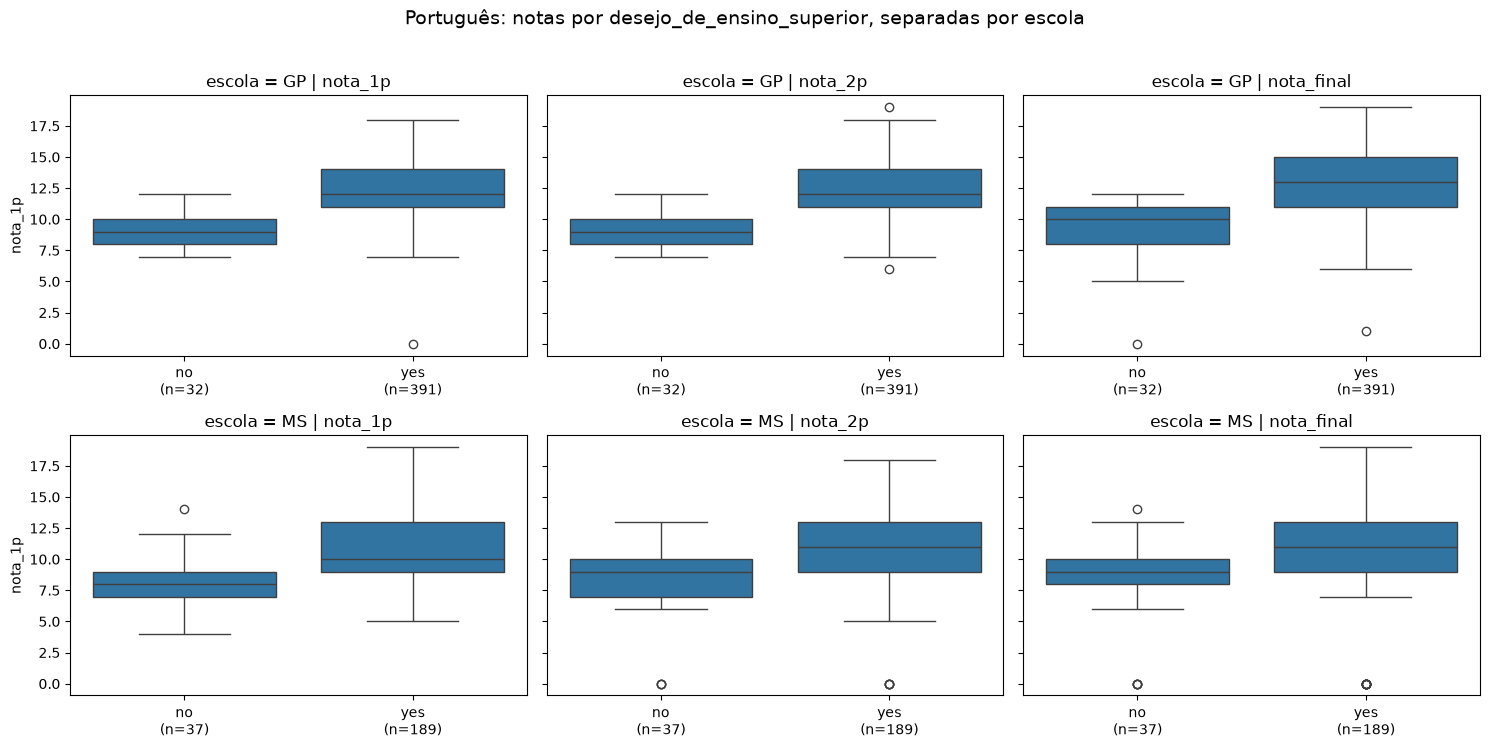

In [ ]:
notas = ["nota_1p", "nota_2p", "nota_final"]
boxplots_por_lente(df_port, notas, "desejo_de_ensino_superior", "escola", titulo="Português")

# Perguntas
- A desvantagem de MS é composição? olhar região, sexo, trabalho da mãe/pai e motivo da escolha da escola.
- O trabalho do pai é mais importante para as notas do que o trabalho do pai?
- 

# Composição de MS:
- Diante do exposto no quarto quartil, percebemos que a escola MS possui menos alunos no quarto quartil, ou seja, com maiores notas. Isso se deve a composição dos alunos?

A escola MS possui 14 alunos com nota zero na terceira prova e alguns zeros na segunda prova. Vou considerar que eles abandonaram o curso e retirá-los do dataframe.

In [151]:
df_port1 = df_port[~(df_port["nota_final"] == 0)]


Português: média das notas por escola e regiao
                 n  nota_1p  nota_2p  nota_final
escola regiao                                   
GP     R        78    11.63    11.60       12.14
       U       344    12.07    12.28       12.71
MS     R       109    10.48    11.01       11.35
       U       103    10.59    10.91       11.36

Diferença de média (U - R) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP         0.44     0.67        0.57
MS         0.12    -0.10        0.01


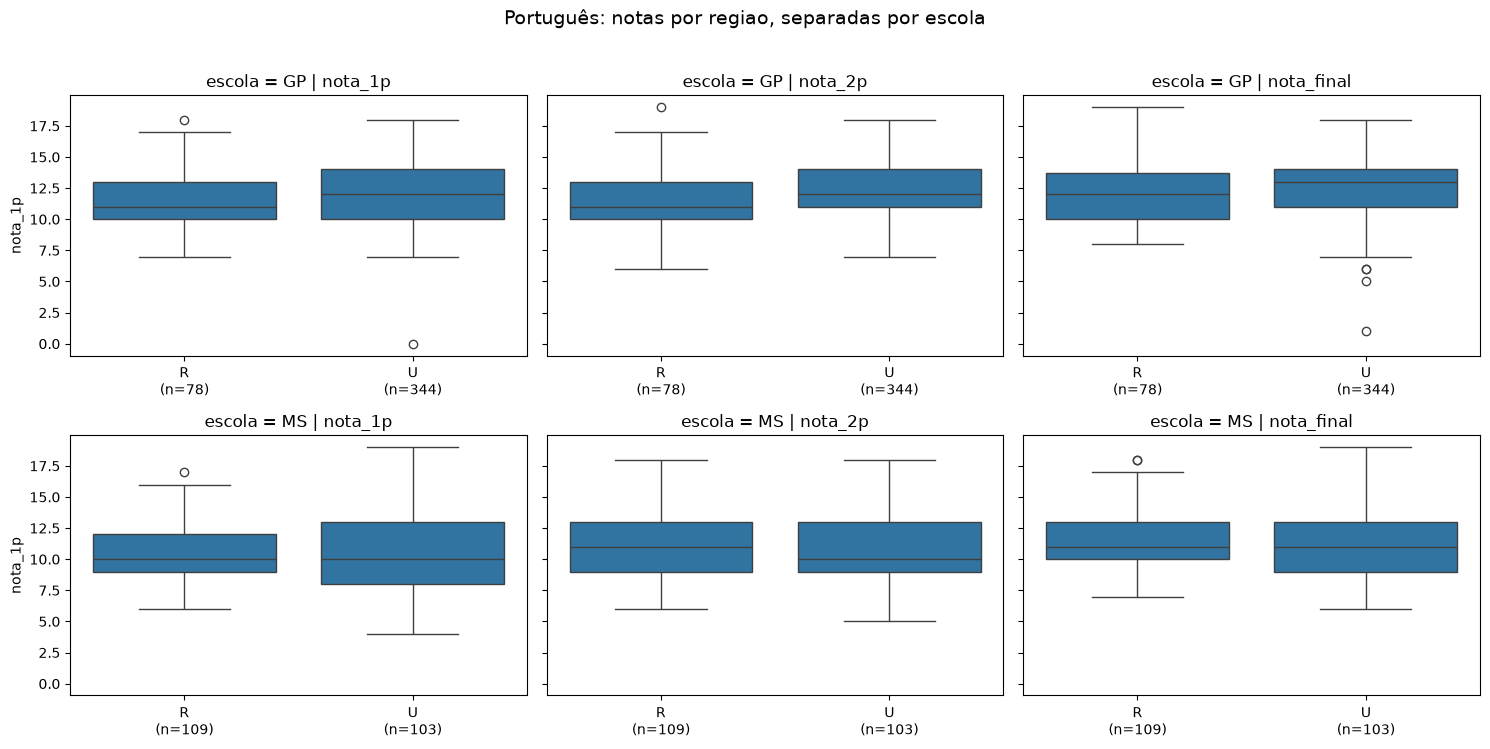

In [152]:
boxplots_por_lente(df_port1, notas, "regiao", "escola", titulo="Português")

A escola MS possui mais alunos da região rural e consequentemente, notas menores.

Português: média das notas por escola e sexo
               n  nota_1p  nota_2p  nota_final
escola sexo                                   
GP     F     237    12.29    12.50       13.00
       M     185    11.61    11.70       12.10
MS     F     139    10.76    11.12       11.59
       M      73    10.11    10.66       10.90

Diferença de média (M - F) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP        -0.68    -0.80       -0.91
MS        -0.65    -0.46       -0.69


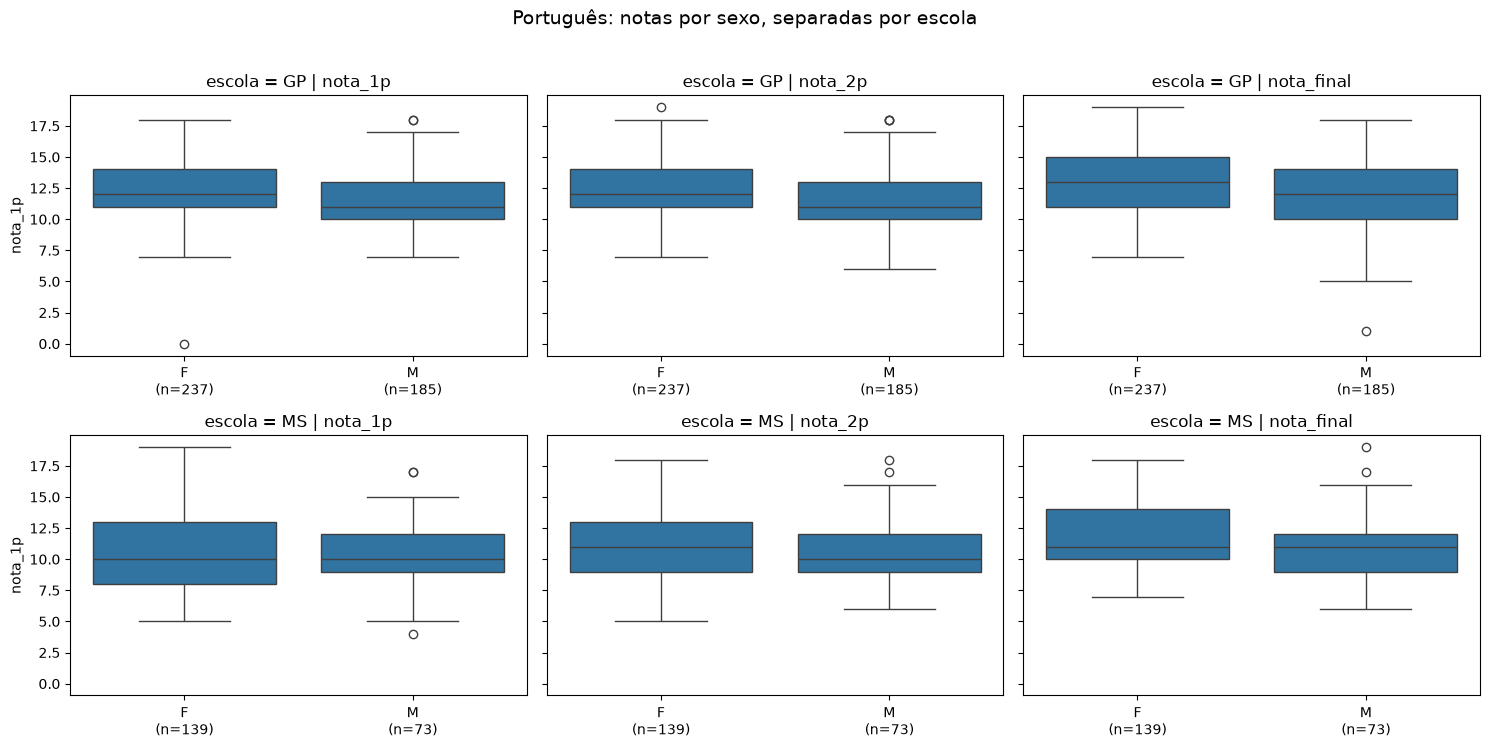

In [153]:
boxplots_por_lente(df_port1, notas, "sexo", "escola", titulo="Português")

- A questão do sexo não parece ser algo muito influenciável aqui, pois possui mais mulheres que homens, apesar das mulheres da escola GP terem notas maiores que as mulheres da MS. 
- A mesma coisa acontece com os homens. Homens da escola GP tem notas maiores que os homens da escola MS.

## Observar o trabalho da mãe/pai e região com as notas.

Português: média das notas por regiao e trabalho_mae
                       n  nota_1p  nota_2p  nota_final
regiao trabalho_mae                                   
R      at_home        59    10.92    11.17       11.47
       health          8    11.00    11.50       11.62
       other          78    10.77    11.15       11.67
       services       28    10.93    10.93       11.21
       teacher        14    12.21    12.71       13.57
U      at_home        72    10.25    10.93       11.31
       health         40    12.68    12.88       13.35
       other         172    11.68    11.80       12.22
       services      107    11.86    12.04       12.50
       teacher        56    12.86    13.00       13.50


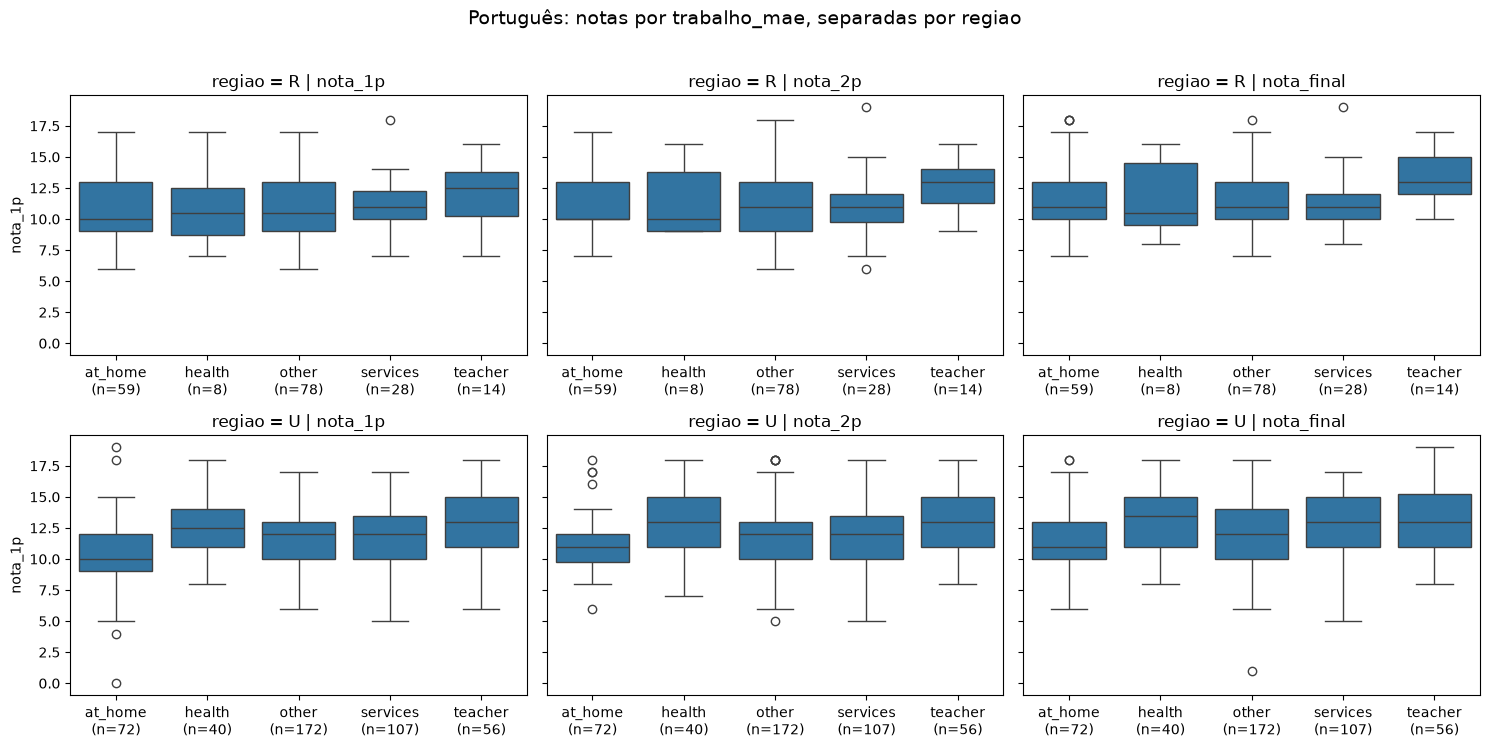

In [ ]:
boxplots_por_lente(df_port1, notas, "trabalho_mae", "regiao", titulo="Português")

- Na região urbana, se percebe que os estudantes com a mãe que trabalham na área da saúde e como professores, possuem notas maiores que o restante.
- Enquanto isso, na região rural, apesar das pequenas quantidade, se percebe que alunos cujas mães são professores, possuem notas maiores.

Português: média das notas por regiao e trabalho_pai
                       n  nota_1p  nota_2p  nota_final
regiao trabalho_pai                                   
R      at_home        10    10.70    11.60       12.00
       health          3    10.00    11.00       11.00
       other         115    10.88    11.18       11.59
       services       51    10.78    10.92       11.39
       teacher         8    13.88    14.12       14.62
U      at_home        31    10.39    10.87       11.61
       health         20    12.35    12.45       12.80
       other         244    11.73    11.97       12.42
       services      125    11.69    11.82       12.19
       teacher        27    13.04    13.41       13.78


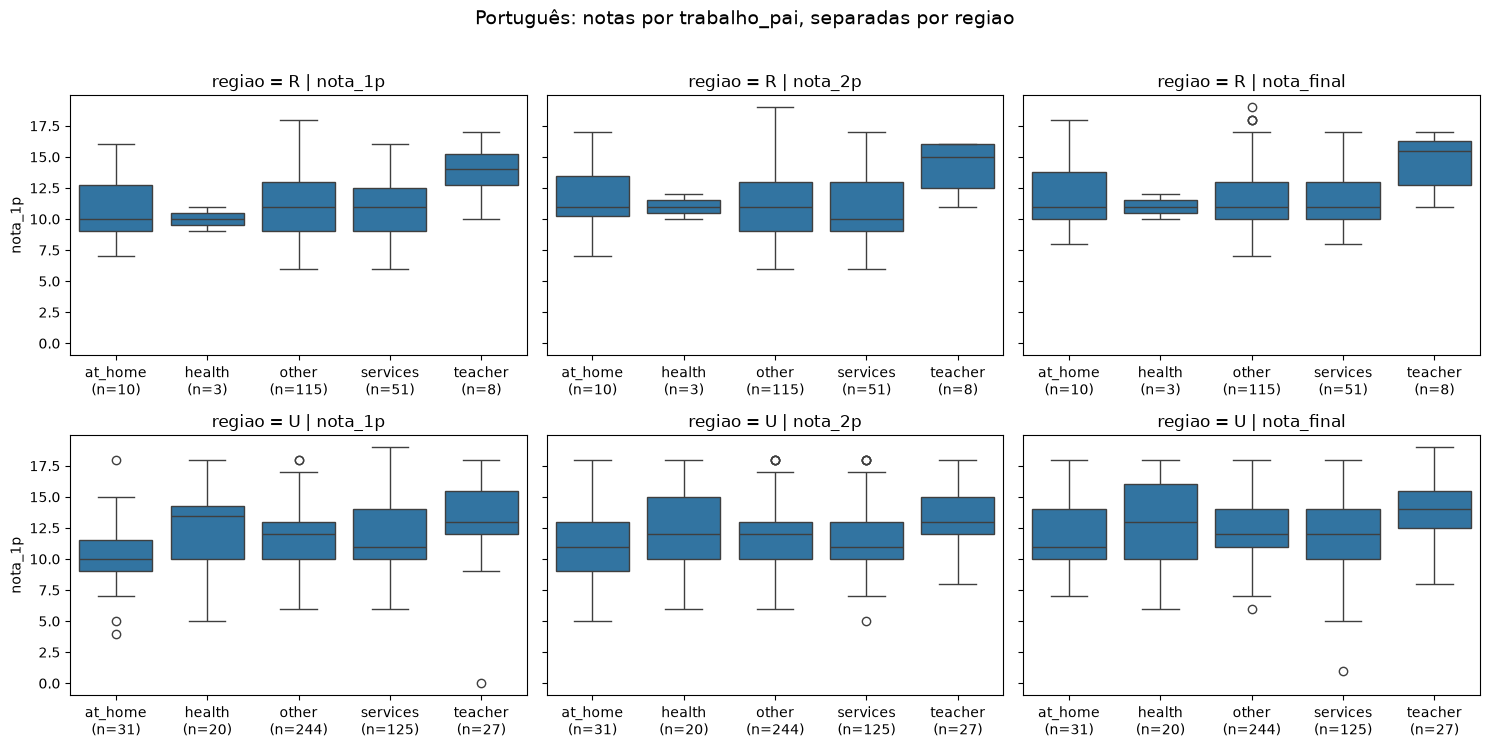

In [157]:
boxplots_por_lente(df_port1, notas, "trabalho_pai", "regiao", titulo="Português")

- Na região urbana, se observa aqui que o mesmo padrão, que filhos cujos pais trabalham com saúde e educação, possuem notas maiores.
- Na região rural, pela grande concentração do trabalho do pai estar em 'other', o boxplot possui uma aparência distorcida. Apesar disso, percebe-se a pequena variância das notas nos alunos cujos pais são professores e, ao mesmo tempo, notas maiores.

Diante disso, posso concluir que em ambas as regiões, filhos de professores e de profissionais da saúde tendem a ter médias maiores. No entanto, o pai só se destaca pontualmente em teacher – especialmente no rural, com n=8 –, enquanto a mãe apresenta associação mais ampla e consitente. No rural, o tamanho amostral impede conclusões firmes.